<a href="https://colab.research.google.com/github/synatkeamsk/rbc-morphology/blob/main/notebooks/colab_train.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!nvidia-smi

Wed Nov 11 04:16:50 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   42C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
# Clone your repo and enter the folder
!git clone https://github.com/synatkeamsk/rbc-morphology.git
%cd rbc-morphology

# Install remaining libraries
!pip install -q timm albumentations opencv-python-headless onnx onnxruntime

Cloning into 'rbc-morphology'...
remote: Enumerating objects: 78, done.
remote: Counting objects: 100% (78/78), done.
remote: Compressing objects: 100% (61/61), done.
remote: Total 78 (delta 26), reused 55 (delta 13), pack-reused 0 (from 0)
Receiving objects: 100% (78/78), 438.48 KiB | 1.78 MiB/s, done.
Resolving deltas: 100% (26/26), done.
/content/rbc-morphology


In [ ]:
!python src/model.py

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd

# Create dummy sample RBC patches
os.makedirs("data/raw/synthetic", exist_ok=True)
os.makedirs("data/splits", exist_ok=True)

records = []
classes = ["normal", "drepanocyte", "dacrocyte", "schistocyte", "echinocyte", "elliptocyte", "spherocyte", "codocyte"]

for i in range(160):
    label_idx = i % len(classes)
    cls_name = classes[label_idx]

    # Create a 224x224 RGB image (simulating a stained RBC crop)
    img = np.random.randint(180, 240, (224, 224, 3), dtype=np.uint8)
    cv2.circle(img, (112, 112), 60, (120, 50, 160), -1) # Cell body
    cv2.circle(img, (112, 112), 25, (220, 200, 220), -1) # Central pallor

    path = f"data/raw/synthetic/cell_{i}_{cls_name}.png"
    cv2.imwrite(path, img)
    records.append({"image_path": path, "label": label_idx})

df = pd.DataFrame(records)
# Split 80% train, 20% val
train_df = df.sample(frac=0.8, random_state=42)
val_df = df.drop(train_df.index)

train_df.to_csv("data/splits/train.csv", index=False)
val_df.to_csv("data/splits/val.csv", index=False)

print(f"Created {len(train_df)} train samples and {len(val_df)} validation samples.")

Created 128 train samples and 32 validation samples.


In [ ]:
%%bash
# Add project root to sys.path in src/train.py
python3 -c "
import sys
content = open('src/train.py').read()
if 'sys.path.append' not in content:
    header = 'import sys\nfrom pathlib import Path\nsys.path.append(str(Path(__file__).resolve().parents[1]))\n\n'
    open('src/train.py', 'w').write(header + content)
"

# Add project root to sys.path in src/infer.py
python3 -c "
import sys
content = open('src/infer.py').read()
if 'sys.path.append' not in content:
    header = 'import sys\nfrom pathlib import Path\nsys.path.append(str(Path(__file__).resolve().parents[1]))\n\n'
    open('src/infer.py', 'w').write(header + content)
"

In [ ]:
import re
from pathlib import Path

# 1. Update backbone name to 'convnext_nano' in all files
for file in ["src/config.py", "src/model.py", "src/train.py", "src/infer.py"]:
    p = Path(file)
    if p.exists():
        content = p.read_text().replace("convnext_nano.in12k_ft_in1k_224", "convnext_nano")
        p.write_text(content)

# 2. Update default workers from 4 to 2 (optimized for Colab's 2 CPU cores)
for file, old_val, new_val in [
    ("src/config.py", "num_workers: int = 4", "num_workers: int = 2"),
    ("src/train.py", "default=4", "default=2"),
]:
    p = Path(file)
    if p.exists():
        p.write_text(p.read_text().replace(old_val, new_val))

# 3. Replace deprecated ShiftScaleRotate with modern Affine in src/data.py
p = Path("src/data.py")
if p.exists():
    content = p.read_text()
    content = re.sub(
        r"A\.ShiftScaleRotate\([^)]*p=0\.7\s*\)",
        "A.Affine(scale=(0.9, 1.1), translate_percent=(-0.06, 0.06), rotate=(-180, 180), border_mode=cv2.BORDER_REFLECT, p=0.7)",
        content,
        flags=re.DOTALL
    )
    p.write_text(content)

print("All fixes applied cleanly!")

All fixes applied cleanly!


In [ ]:
!python -m src.train \
    --train_csv data/splits/train.csv \
    --val_csv data/splits/val.csv \
    --num_classes 8 \
    --backbone convnext_nano \
    --epochs 5 \
    --batch_size 16 \
    --num_workers 2 \
    --device cuda


model.safetensors: downloading bytes:  95% 59.5M/62.4M [00:01<00:00, 89.1MB/s, 4.40MB/s  ]
model.safetensors: downloading bytes: 100% 59.5M/59.5M [00:01<00:00, 45.6MB/s, 5.72MB/s  ]
model.safetensors: reconstructing file: 100% 62.4M/62.4M [00:01<00:00, 47.9MB/s, 6.02MB/s  ]
/content/rbc-morphology/src/train.py:109: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
Starting SmearScope training loop...
Training:   0% 0/8 [00:00<?, ?it/s]/content/rbc-morphology/src/train.py:46: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Validating:   0% 0/2 [00:00<?, ?it/s]/content/rbc-morphology/src/train.py:71: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Epoch [01/05] Train Loss: 0.0208 | Train Acc: 0.172 | Va

In [ ]:
!pip install -q onnxscript

In [ ]:
!python -m src.infer \
    --export \
    --checkpoint checkpoints/best_smearscope.pt \
    --onnx_path checkpoints/best_smearscope.onnx \
    --num_classes 8

Loading checkpoint: checkpoints/best_smearscope.pt
Exporting ONNX: checkpoints/best_smearscope.onnx
/content/rbc-morphology/src/infer.py:102: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(
[torch.onnx] Obtain model graph for `SmearScopeClassifier([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `SmearScopeClassifier([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
[*] ONNX model successfully verified!


In [ ]:
from src.infer import SmearPredictor

# Target classes
classes = ["normal", "drepanocyte", "dacrocyte", "schistocyte", "echinocyte", "elliptocyte", "spherocyte", "codocyte"]

# Initialize ONNX inference engine
predictor = SmearPredictor(
    model_path="checkpoints/best_smearscope.onnx",
    classes=classes,
    backend="onnx"
)

# Test on one of synthetic RBC images
sample_image = "data/raw/synthetic/cell_0_normal.png"
result = predictor.predict(sample_image)

print(f"Predicted Class: {result['prediction']}")
print(f"Confidence:      {result['confidence'] * 100:.2f}%\n")
print("Class Probabilities:")
for cls, prob in result["probabilities"].items():
    print(f"  - {cls:<12}: {prob * 100:6.2f}%")

Predicted Class: dacrocyte
Confidence:      19.63%

Class Probabilities:
  - normal      :  11.66%
  - drepanocyte :  19.34%
  - dacrocyte   :  19.63%
  - schistocyte :   6.54%
  - echinocyte  :  12.17%
  - elliptocyte :   8.21%
  - spherocyte  :  16.07%
  - codocyte    :   6.38%


In [ ]:
# Clean previous runs, clone fresh, and enter directory
!rm -rf rbc-morphology
!git clone https://github.com/synatkeamsk/rbc-morphology.git
%cd rbc-morphology

# Verify NVIDIA T4 GPU is assigned
!nvidia-smi

Cloning into 'rbc-morphology'...
remote: Enumerating objects: 82, done.
remote: Counting objects: 100% (82/82), done.
remote: Compressing objects: 100% (65/65), done.
remote: Total 82 (delta 28), reused 55 (delta 13), pack-reused 0 (from 0)
Receiving objects: 100% (82/82), 440.04 KiB | 1.76 MiB/s, done.
Resolving deltas: 100% (28/28), done.
/content/rbc-morphology/rbc-morphology
Wed Nov 11 04:18:17 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=================================

In [ ]:
!pip install -q timm albumentations opencv-python-headless onnx onnxruntime

In [ ]:
# 1. Download raw smears
!mkdir -p data/raw
!git clone https://github.com/Chula-PIC-Lab/Chula-RBC-12-Dataset.git data/raw/chula_rbc_12

# 2. Extract single-cell patches and generate train/val splits
!python src/prepare_chula_rbc.py

Cloning into 'data/raw/chula_rbc_12'...
remote: Enumerating objects: 1848, done.
remote: Counting objects: 100% (4/4), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 1848 (delta 2), reused 1 (delta 1), pack-reused 1844 (from 1)
Receiving objects: 100% (1848/1848), 192.95 MiB | 26.86 MiB/s, done.
Resolving deltas: 100% (240/240), done.
Found 738 full blood smear images in data/raw/chula_rbc_12/Dataset...
Cropping single RBCs: 100% 738/738 [00:15<00:00, 47.84it/s]

Successfully extracted 21922 single RBC crops!

Class distribution:
class_name
normal         6330
spherocyte     3449
target_cell    2753
ovalocyte      2140
stomatocyte    1996
hypochromia    1063
elliptocyte    1052
schistocyte     897
burr_cell       785
macrocyte       689
microcyte       461
teardrop        307
Name: count, dtype: int64

[*] Class mapping saved to: data/splits/class_mapping.json
[*] Training split saved (17537 cells): data/splits/train.csv
[*] Validation split saved (4385 cells): data

In [ ]:
!python -m src.train \
    --train_csv data/splits/train.csv \
    --val_csv data/splits/val.csv \
    --num_classes 12 \
    --backbone convnext_nano \
    --epochs 25 \
    --batch_size 32 \
    --num_workers 2 \
    --lr 3e-4 \
    --device cuda

/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/content/rbc-morphology/rbc-morphology/src/train.py:105: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
Starting SmearScope training loop...
Training:   0% 0/548 [00:00<?, ?it/s]/content/rbc-morphology/rbc-morphology/src/train.py:42: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Validating:   0% 0/138 [00:00<?, ?it/s]/content/rbc-morphology/rbc-morphology/src/train.py:67: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Epoch [01/25] Train Loss: 0.0043 | Train Acc: 0.080 | Va

In [ ]:

#Step 1: Export to ONNX for Production
#Convert trained PyTorch checkpoint (checkpoints/best_smearscope.pt) into an optimized ONNX format. This makes inference up to 3–5× faster and allows the model to run without needing a heavy PyTorch GPU environment.

!python -m src.infer \
    --export \
    --checkpoint checkpoints/best_smearscope.pt \
    --onnx_path checkpoints/best_smearscope.onnx \
    --num_classes 12

Loading checkpoint: checkpoints/best_smearscope.pt
Exporting ONNX: checkpoints/best_smearscope.onnx
/content/rbc-morphology/rbc-morphology/src/infer.py:98: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(
[torch.onnx] Obtain model graph for `SmearScopeClassifier([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `SmearScopeClassifier([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
[*] ONNX model successfully verified!


In [ ]:
# Step 2: Download the Trained Model
from google.colab import files

# 1. Download your trained PyTorch weights
files.download("checkpoints/best_smearscope.pt")

# 2. Download the fast ONNX model
files.download("checkpoints/best_smearscope.onnx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Loading checkpoint from checkpoints/best_smearscope.pt...
Running validation inference...


Evaluating: 100%|██████████| 138/138 [00:19<00:00,  7.17it/s]


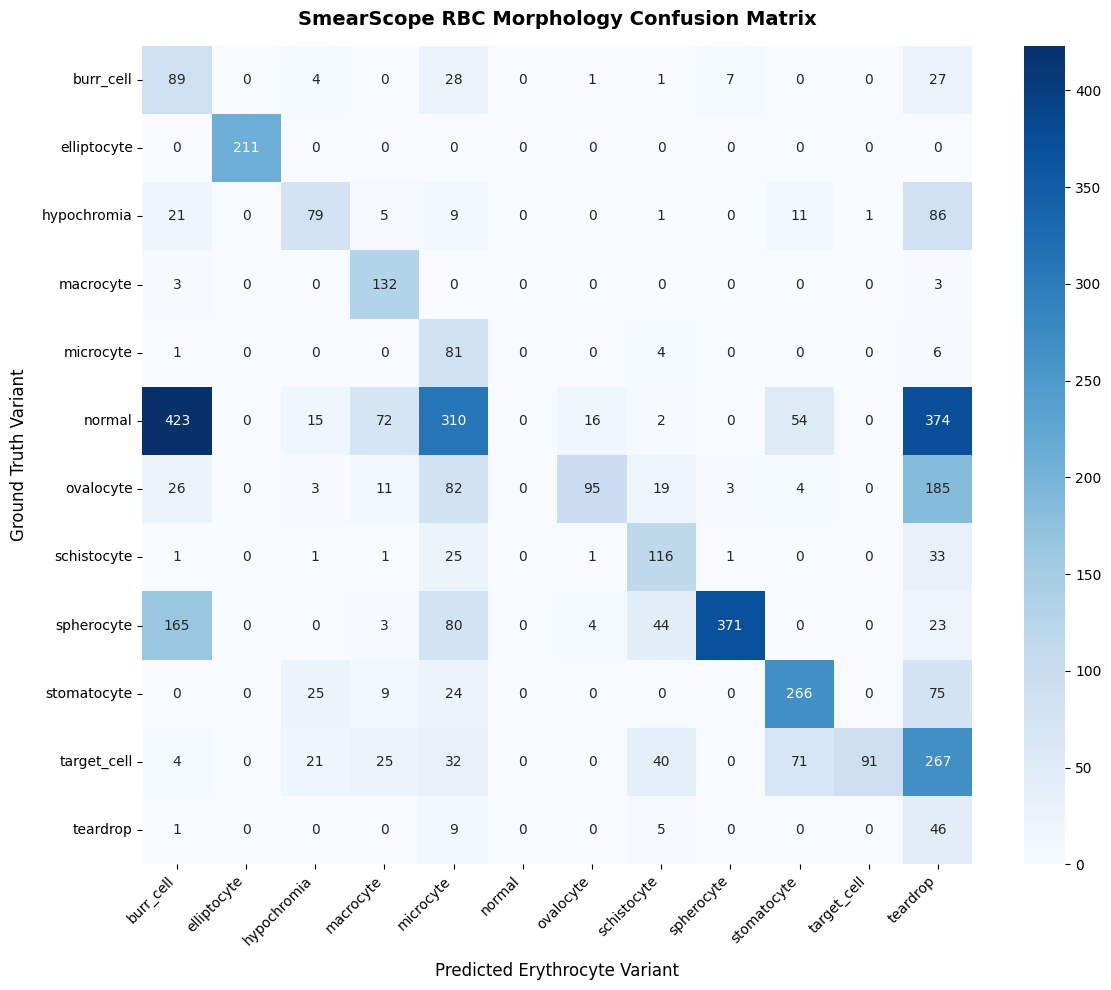


--- Validation Classification Report ---
              precision    recall  f1-score   support

   burr_cell     0.1213    0.5669    0.1998       157
 elliptocyte     1.0000    1.0000    1.0000       211
 hypochromia     0.5338    0.3709    0.4377       213
   macrocyte     0.5116    0.9565    0.6667       138
   microcyte     0.1191    0.8804    0.2098        92
      normal     0.0000    0.0000    0.0000      1266
   ovalocyte     0.8120    0.2220    0.3486       428
 schistocyte     0.5000    0.6480    0.5645       179
  spherocyte     0.9712    0.5377    0.6922       690
 stomatocyte     0.6552    0.6667    0.6609       399
 target_cell     0.9891    0.1652    0.2830       551
    teardrop     0.0409    0.7541    0.0776        61

    accuracy                         0.3596      4385
   macro avg     0.5212    0.5640    0.4284      4385
weighted avg     0.5339    0.3596    0.3647      4385



In [ ]:
#Step 3: Generate the Confusion Matrix
# To assess the model's clinical diagnostic capability (e.g., Is the model successfully detecting rare schistocytes, or is it confusing them with normal cells?), generate a 12×12 Confusion Matrix heatmap:

import os
import json
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
from torch.utils.data import DataLoader
from tqdm import tqdm

from src.data import RBCDataset, get_transforms
from src.model import get_model

# 1. Device and paths
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
checkpoint_path = "checkpoints/best_smearscope.pt"
val_csv = "data/splits/val.csv"
mapping_path = "data/splits/class_mapping.json"

# 2. Load class names in exact numerical order
with open(mapping_path) as f:
    class_map = json.load(f)
class_names = [k for k, v in sorted(class_map.items(), key=lambda item: item[1])]
num_classes = len(class_names)

# 3. Load trained ConvNeXt weights
print(f"Loading checkpoint from {checkpoint_path}...")
model = get_model(num_classes=num_classes, backbone_name="convnext_nano", pretrained=False, device=device)
checkpoint = torch.load(checkpoint_path, map_location=device)
state_dict = checkpoint.get("model_state_dict", checkpoint)
model.load_state_dict(state_dict)
model.eval()

# 4. Prepare Validation DataLoader
val_df = pd.read_csv(val_csv)
val_dataset = RBCDataset(val_df, transform=get_transforms(img_size=224, is_train=False))
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

# 5. Run inference across the validation dataset
all_preds = []
all_targets = []

print("Running validation inference...")
with torch.no_grad():
    for images, targets in tqdm(val_loader, desc="Evaluating"):
        images = images.to(device)
        outputs = model(images)
        preds = outputs.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_targets.extend(targets.numpy())

# 6. Compute Confusion Matrix
cm = confusion_matrix(all_targets, all_preds)

# 7. Plot Heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar=True
)
plt.title("SmearScope RBC Morphology Confusion Matrix", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Predicted Erythrocyte Variant", fontsize=12, labelpad=10)
plt.ylabel("Ground Truth Variant", fontsize=12, labelpad=10)
plt.xticks(rotation=45, ha="right", fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()

# Save the plot for your README
os.makedirs("docs/assets", exist_ok=True)
plt.savefig("docs/assets/confusion_matrix.png", dpi=300)
plt.show()

# 8. Print full classification metrics
print("\n--- Validation Classification Report ---")
print(classification_report(all_targets, all_preds, target_names=class_names, digits=4, zero_division=0))

In [ ]:
#  Download the baseline confusion matrix image
files.download("docs/assets/confusion_matrix.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
#Add import numpy as np to src/train.py
with open("src/train.py", "r") as f:
    content = f.read()

# Add import numpy as np at the top if missing
if "import numpy as np" not in content:
    content = "import numpy as np\n" + content

with open("src/train.py", "w") as f:
    f.write(content)

print("Added 'import numpy as np' to src/train.py successfully!")

Added 'import numpy as np' to src/train.py successfully!


In [ ]:
#second model training
!python -m src.train \
    --train_csv data/splits/train.csv \
    --val_csv data/splits/val.csv \
    --num_classes 12 \
    --backbone convnext_nano \
    --epochs 25 \
    --batch_size 32 \
    --num_workers 2 \
    --lr 3e-4 \
    --device cuda

/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/content/rbc-morphology/rbc-morphology/src/train.py:106: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
Starting SmearScope training loop...
Training:   0% 0/548 [00:00<?, ?it/s]/content/rbc-morphology/rbc-morphology/src/train.py:43: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Validating:   0% 0/138 [00:00<?, ?it/s]/content/rbc-morphology/rbc-morphology/src/train.py:68: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Epoch [01/25] Train Loss: 0.0036 | Train Acc: 0.180 | Va

Running validation evaluation...


Evaluating: 100%|██████████| 138/138 [00:14<00:00,  9.56it/s]


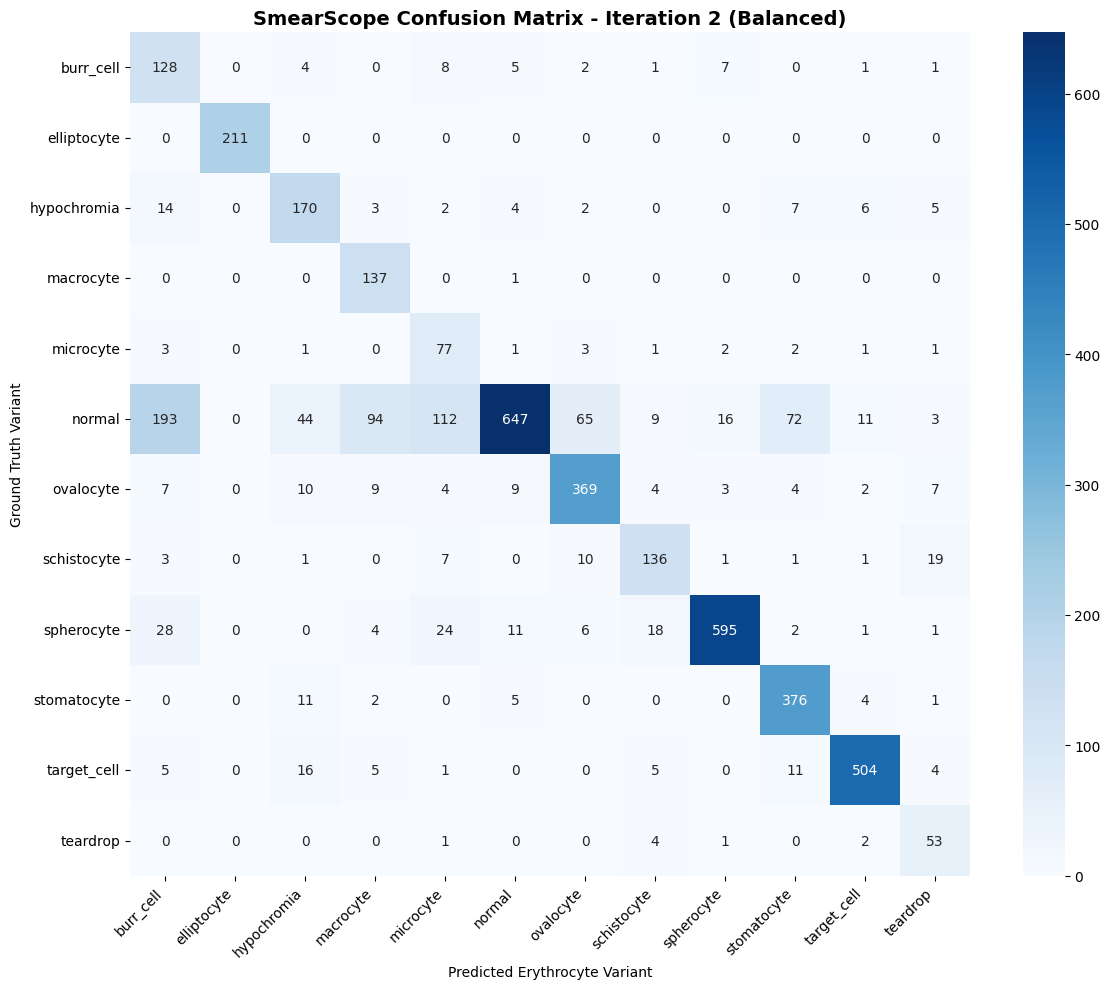


--- Validation Classification Report (Iteration 2) ---
              precision    recall  f1-score   support

   burr_cell     0.3360    0.8153    0.4758       157
 elliptocyte     1.0000    1.0000    1.0000       211
 hypochromia     0.6615    0.7981    0.7234       213
   macrocyte     0.5394    0.9928    0.6990       138
   microcyte     0.3263    0.8370    0.4695        92
      normal     0.9473    0.5111    0.6639      1266
   ovalocyte     0.8074    0.8621    0.8339       428
 schistocyte     0.7640    0.7598    0.7619       179
  spherocyte     0.9520    0.8623    0.9049       690
 stomatocyte     0.7916    0.9424    0.8604       399
 target_cell     0.9456    0.9147    0.9299       551
    teardrop     0.5579    0.8689    0.6795        61

    accuracy                         0.7761      4385
   macro avg     0.7191    0.8470    0.7502      4385
weighted avg     0.8480    0.7761    0.7833      4385



In [ ]:
# Confusion matrix
import os
import json
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
from torch.utils.data import DataLoader
from tqdm import tqdm

from src.data import RBCDataset, get_transforms
from src.model import get_model

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
checkpoint_path = "checkpoints/best_smearscope.pt"
val_csv = "data/splits/val.csv"
mapping_path = "data/splits/class_mapping.json"

# Load class names
with open(mapping_path) as f:
    class_map = json.load(f)
class_names = [k for k, v in sorted(class_map.items(), key=lambda item: item[1])]
num_classes = len(class_names)

# Load model
model = get_model(num_classes=num_classes, backbone_name="convnext_nano", pretrained=False, device=device)
checkpoint = torch.load(checkpoint_path, map_location=device)
state_dict = checkpoint.get("model_state_dict", checkpoint)
model.load_state_dict(state_dict)
model.eval()

# DataLoader
val_df = pd.read_csv(val_csv)
val_dataset = RBCDataset(val_df, transform=get_transforms(img_size=224, is_train=False))
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

all_preds = []
all_targets = []

print("Running validation evaluation...")
with torch.no_grad():
    for images, targets in tqdm(val_loader, desc="Evaluating"):
        images = images.to(device)
        outputs = model(images)
        preds = outputs.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_targets.extend(targets.numpy())

# Plot Heatmap
cm = confusion_matrix(all_targets, all_preds)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title("SmearScope Confusion Matrix - Iteration 2 (Balanced)", fontsize=14, fontweight="bold")
plt.xlabel("Predicted Erythrocyte Variant")
plt.ylabel("Ground Truth Variant")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("docs/assets/confusion_matrix_balanced.png", dpi=300)
plt.show()

# Print metrics
print("\n--- Validation Classification Report (Iteration 2) ---")
print(classification_report(all_targets, all_preds, target_names=class_names, digits=4, zero_division=0))

In [ ]:
!python -m src.infer \
    --export \
    --checkpoint checkpoints/best_smearscope.pt \
    --onnx_path checkpoints/best_smearscope.onnx \
    --num_classes 12

Loading checkpoint: checkpoints/best_smearscope.pt
Exporting ONNX: checkpoints/best_smearscope.onnx
/content/rbc-morphology/rbc-morphology/src/infer.py:98: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(
[torch.onnx] Obtain model graph for `SmearScopeClassifier([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `SmearScopeClassifier([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
[*] ONNX model successfully verified!


In [ ]:
from google.colab import files

# 1. Download the new balanced PyTorch weights
files.download("checkpoints/best_smearscope.pt")

# 2. Download the fast ONNX model for deployment
files.download("checkpoints/best_smearscope.onnx")

# 3. Download the new balanced confusion matrix
files.download("docs/assets/confusion_matrix_balanced.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!ls

sample_data


In [ ]:
#' 11/11/2026

#' 3rd iteration using last best_smearscope model from 2nd iteration
#' 1. Clean and clone the freshly updated repo
!rm -rf rbc-morphology
!git clone https://github.com/synatkeamsk/rbc-morphology.git
%cd rbc-morphology

# 2. Install dependencies
!pip install -q timm albumentations opencv-python-headless onnx onnxruntime

# 3. Pull raw Chula dataset & crop validation cells
!mkdir -p data/raw
!git clone https://github.com/Chula-PIC-Lab/Chula-RBC-12-Dataset.git data/raw/chula_rbc_12
!python src/prepare_chula_rbc.py

Cloning into 'rbc-morphology'...
remote: Enumerating objects: 95, done.
remote: Counting objects: 100% (95/95), done.
remote: Compressing objects: 100% (77/77), done.
remote: Total 95 (delta 36), reused 57 (delta 14), pack-reused 0 (from 0)
Receiving objects: 100% (95/95), 638.84 KiB | 2.51 MiB/s, done.
Resolving deltas: 100% (36/36), done.
/content/rbc-morphology
Cloning into 'data/raw/chula_rbc_12'...
remote: Enumerating objects: 1848, done.
remote: Counting objects: 100% (4/4), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 1848 (delta 2), reused 1 (delta 1), pack-reused 1844 (from 1)
Receiving objects: 100% (1848/1848), 192.95 MiB | 18.82 MiB/s, done.
Resolving deltas: 100% (240/240), done.
Found 738 full blood smear images in data/raw/chula_rbc_12/Dataset...
Cropping single RBCs: 100% 738/738 [00:16<00:00, 45.42it/s]

Successfully extracted 21922 single RBC crops!

Class distribution:
class_name
normal         6330
spherocyte     3449
target_cell    2753
ovaloc

In [ ]:
import os
import shutil
from google.colab import files

os.makedirs("checkpoints", exist_ok=True)
print("Click 'Choose Files' below and select 'best_smearscope.pt' from your D: drive:")
uploaded = files.upload()

for filename in uploaded.keys():
    shutil.move(filename, "checkpoints/best_smearscope.pt")

print("[*] Successfully loaded checkpoints/best_smearscope.pt into Colab!")

Click 'Choose Files' below and select 'best_smearscope.pt' from your D: drive:


Saving best_smearscope.pt to best_smearscope.pt
[*] Successfully loaded checkpoints/best_smearscope.pt into Colab!


Extracting probabilities from validation set...


100%|██████████| 138/138 [00:15<00:00,  9.01it/s]



BASELINE (Argmax): Normal Recall: 647/1266 (51.1%) | Schistocyte Recall: 136/179 (76.0%)
Abnormal Threshold   | Normal Recall      | Schistocyte Recall
-----------------------------------------------------------------
Threshold >= 0.45       |   85.3%             |   68.7%
Threshold >= 0.50       |   90.0%             |   63.1%
Threshold >= 0.55       |   93.8%             |   54.7%
Threshold >= 0.60       |   96.1%             |   48.0%
Threshold >= 0.65       |   97.8%             |   39.7%
Threshold >= 0.70       |   98.9%             |   30.7%


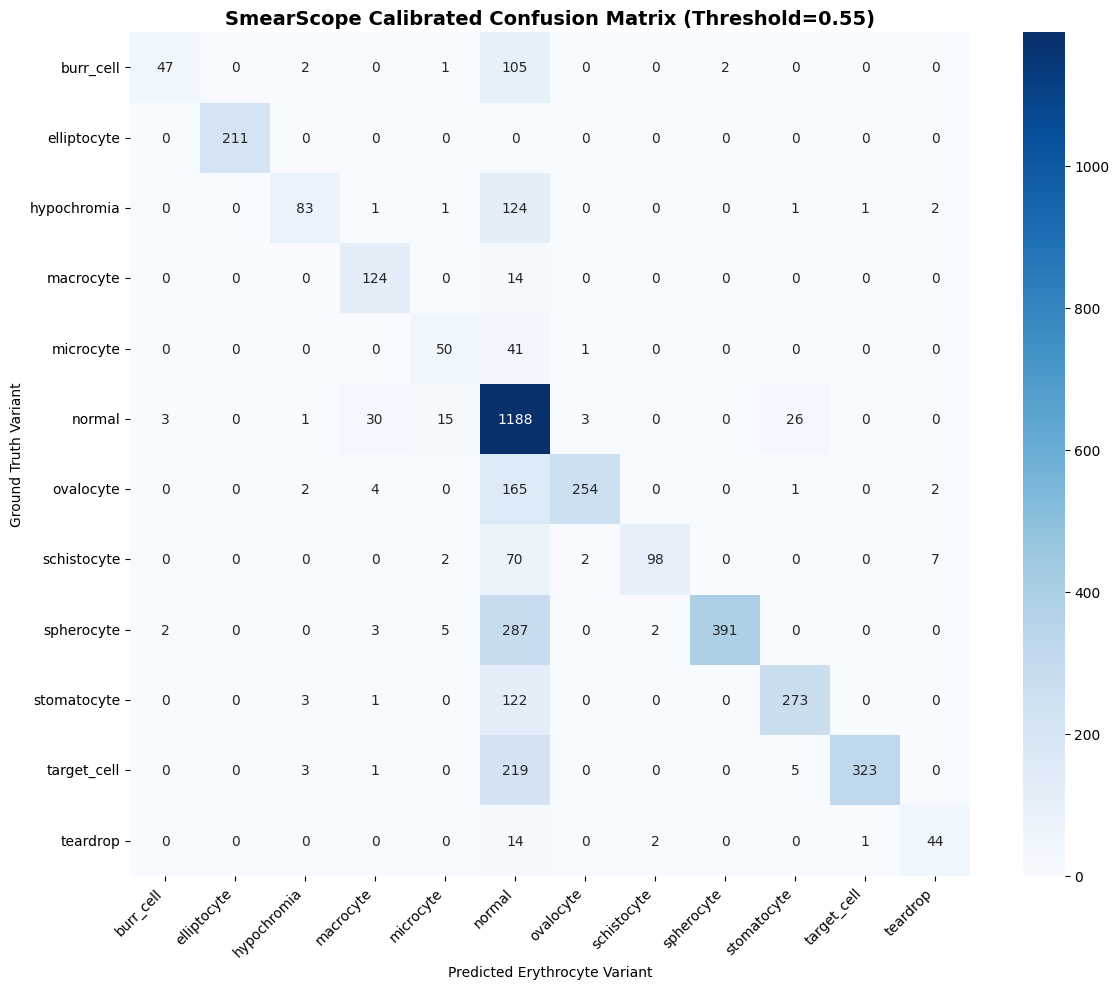

In [ ]:
#' Run the Clinical Threshold Sweep
import os
import json
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
from torch.utils.data import DataLoader
from tqdm import tqdm

from src.data import RBCDataset, get_transforms
from src.model import get_model

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
checkpoint_path = "checkpoints/best_smearscope.pt"
val_csv = "data/splits/val.csv"
mapping_path = "data/splits/class_mapping.json"

# 1. Load classes
with open(mapping_path) as f:
    class_map = json.load(f)
class_names = [k for k, v in sorted(class_map.items(), key=lambda item: item[1])]
num_classes = len(class_names)
normal_idx = class_names.index("normal")
schisto_idx = class_names.index("schistocyte")

# 2. Load model
model = get_model(num_classes=num_classes, backbone_name="convnext_nano", pretrained=False, device=device)
checkpoint = torch.load(checkpoint_path, map_location=device)
state_dict = checkpoint.get("model_state_dict", checkpoint)
model.load_state_dict(state_dict)
model.eval()

# 3. DataLoader
val_df = pd.read_csv(val_csv)
val_dataset = RBCDataset(val_df, transform=get_transforms(img_size=224, is_train=False))
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

# 4. Extract raw probabilities
all_probs = []
all_targets = []
print("Extracting probabilities from validation set...")
with torch.no_grad():
    for images, targets in tqdm(val_loader):
        images = images.to(device)
        logits = model(images)
        probs = torch.softmax(logits, dim=1).cpu().numpy()
        all_probs.extend(probs)
        all_targets.extend(targets.numpy())

all_probs = np.array(all_probs)
all_targets = np.array(all_targets)
raw_preds = np.argmax(all_probs, axis=1)

# Baseline metrics
total_normal = np.sum(all_targets == normal_idx)
baseline_normal_correct = np.sum((raw_preds == normal_idx) & (all_targets == normal_idx))
total_schisto = np.sum(all_targets == schisto_idx)
baseline_schisto_correct = np.sum((raw_preds == schisto_idx) & (all_targets == schisto_idx))

print("\n" + "="*65)
print(f"BASELINE (Argmax): Normal Recall: {baseline_normal_correct}/{total_normal} ({baseline_normal_correct/total_normal*100:.1f}%) | Schistocyte Recall: {baseline_schisto_correct}/{total_schisto} ({baseline_schisto_correct/total_schisto*100:.1f}%)")
print("="*65)

# 5. Threshold Sweep Table
print(f"{'Abnormal Threshold':<20} | {'Normal Recall':<18} | {'Schistocyte Recall':<18}")
print("-" * 65)

best_threshold = 0.55
for th in [0.45, 0.50, 0.55, 0.60, 0.65, 0.70]:
    temp_preds = []
    for p in all_probs:
        top_cls = int(np.argmax(p))
        if top_cls != normal_idx and p[top_cls] < th:
            temp_preds.append(normal_idx)
        else:
            temp_preds.append(top_cls)
    temp_preds = np.array(temp_preds)

    n_rec = np.sum((temp_preds == normal_idx) & (all_targets == normal_idx)) / total_normal * 100
    s_rec = np.sum((temp_preds == schisto_idx) & (all_targets == schisto_idx)) / total_schisto * 100
    print(f"Threshold >= {th:<10.2f} | {n_rec:6.1f}%             | {s_rec:6.1f}%")

# 6. Apply Optimal Calibrated Threshold (0.55) & Plot Matrix
SELECTED_TH = 0.55
calibrated_preds = []
for p in all_probs:
    top_cls = int(np.argmax(p))
    if top_cls != normal_idx and p[top_cls] < SELECTED_TH:
        calibrated_preds.append(normal_idx)
    else:
        calibrated_preds.append(top_cls)

cm_cal = confusion_matrix(all_targets, calibrated_preds)
plt.figure(figsize=(12, 10))
sns.heatmap(cm_cal, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title(f"SmearScope Calibrated Confusion Matrix (Threshold={SELECTED_TH})", fontsize=14, fontweight="bold")
plt.xlabel("Predicted Erythrocyte Variant")
plt.ylabel("Ground Truth Variant")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
#' Lauch fresh iteration 4
#' Update src/data.py (Lock cell size)
data_code = """
import os
from typing import Callable, Optional, Tuple
import cv2
import pandas as pd
import torch
from torch.utils.data import DataLoader, Dataset
import albumentations as A
from albumentations.pytorch import ToTensorV2


def get_transforms(img_size: int = 224, is_train: bool = True) -> A.Compose:
    \"\"\"
    Stain-robust and orientation-invariant augmentations.
    CRITICAL: scale_limit is set to 0.0 to strictly preserve true biological cell size.
    \"\"\"
    if is_train:
        return A.Compose([
            A.Resize(img_size, img_size),
            A.HorizontalFlip(p=0.5),
            A.VerticalFlip(p=0.5),
            A.RandomRotate90(p=0.5),
            # Full 360 rotation and mild shift, ZERO scaling (scale_limit=0.0)
            A.ShiftScaleRotate(
                shift_limit=0.04,
                scale_limit=0.0,
                rotate_limit=180,
                border_mode=cv2.BORDER_REFLECT,
                p=0.7
            ),
            # Wright-Giemsa stain variation tolerance
            A.ColorJitter(
                brightness=0.12,
                contrast=0.12,
                saturation=0.15,
                hue=0.04,
                p=0.5
            ),
            A.Normalize(
                mean=(0.485, 0.456, 0.406),
                std=(0.229, 0.224, 0.225)
            ),
            ToTensorV2()
        ])
    else:
        return A.Compose([
            A.Resize(img_size, img_size),
            A.Normalize(
                mean=(0.485, 0.456, 0.406),
                std=(0.229, 0.224, 0.225)
            ),
            ToTensorV2()
        ])


class RBCDataset(Dataset):
    def __init__(self, df: pd.DataFrame, transform: Optional[Callable] = None):
        self.df = df.reset_index(drop=True)
        self.transform = transform
        self.image_paths = self.df["image_path"].values
        self.labels = self.df["label"].values

    def __len__(self) -> int:
        return len(self.image_paths)

    def __getitem__(self, idx: int) -> Tuple[torch.Tensor, torch.Tensor]:
        image_path = self.image_paths[idx]
        image = cv2.imread(image_path)
        if image is None:
            raise FileNotFoundError(f"Failed to read image at: {image_path}")

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        if self.transform is not None:
            augmented = self.transform(image=image)
            image = augmented["image"]

        label = torch.tensor(self.labels[idx], dtype=torch.long)
        return image, label


def create_dataloaders(
    train_df: pd.DataFrame,
    val_df: pd.DataFrame,
    img_size: int = 224,
    batch_size: int = 32,
    num_workers: int = 2
) -> Tuple[DataLoader, DataLoader]:
    train_ds = RBCDataset(train_df, transform=get_transforms(img_size, is_train=True))
    val_ds = RBCDataset(val_df, transform=get_transforms(img_size, is_train=False))

    train_loader = DataLoader(
        train_ds, batch_size=batch_size, shuffle=True,
        num_workers=num_workers, pin_memory=torch.cuda.is_available(), drop_last=True
    )
    val_loader = DataLoader(
        val_ds, batch_size=batch_size, shuffle=False,
        num_workers=num_workers, pin_memory=torch.cuda.is_available(), drop_last=False
    )
    return train_loader, val_loader
"""

with open("src/data.py", "w") as f:
    f.write(data_code.strip())

print("[*] src/data.py updated: Cell size scaling locked to 1.0 (zero distortion)!")

[*] src/data.py updated: Cell size scaling locked to 1.0 (zero distortion)!


In [ ]:
#' Update src/train.py (Differential Learning Rates & Pure Cross-Entropy)
train_code = """
import os
import argparse
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.amp import GradScaler, autocast
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
from sklearn.metrics import classification_report, f1_score
from tqdm import tqdm

from src.data import create_dataloaders
from src.model import get_model


def train_one_epoch(model, loader, criterion, optimizer, scaler, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, targets in tqdm(loader, desc="Training", leave=False):
        images, targets = images.to(device, non_blocking=True), targets.to(device, non_blocking=True)
        optimizer.zero_grad()

        with autocast(device_type="cuda" if device.type == "cuda" else "cpu"):
            outputs = model(images)
            loss = criterion(outputs, targets)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)
        _, preds = outputs.max(1)
        correct += preds.eq(targets).sum().item()
        total += targets.size(0)

    return running_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    all_preds = []
    all_targets = []

    for images, targets in tqdm(loader, desc="Validating", leave=False):
        images, targets = images.to(device, non_blocking=True), targets.to(device, non_blocking=True)

        with autocast(device_type="cuda" if device.type == "cuda" else "cpu"):
            outputs = model(images)
            loss = criterion(outputs, targets)

        running_loss += loss.item() * images.size(0)
        _, preds = outputs.max(1)

        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(targets.cpu().numpy())

    val_loss = running_loss / len(all_targets)
    macro_f1 = f1_score(all_targets, all_preds, average="macro", zero_division=0)
    return val_loss, macro_f1, all_targets, all_preds


def main(args):
    device = torch.device(args.device if torch.cuda.is_available() else "cpu")
    os.makedirs(args.checkpoint_dir, exist_ok=True)

    print(f"Loading metadata from {args.train_csv} and {args.val_csv}...")
    train_df = pd.read_csv(args.train_csv)
    val_df = pd.read_csv(args.val_csv)

    train_loader, val_loader = create_dataloaders(
        train_df=train_df,
        val_df=val_df,
        img_size=args.img_size,
        batch_size=args.batch_size,
        num_workers=args.num_workers
    )

    print(f"Building model: {args.backbone} with {args.num_classes} classes...")
    model = get_model(num_classes=args.num_classes, backbone_name=args.backbone, device=device)

    # Standard unweighted Cross-Entropy (clean loss surface)
    criterion = nn.CrossEntropyLoss()

    # Differential Learning Rates: Gentle on backbone, fast on classifier head
    backbone_params = [p for n, p in model.named_parameters() if "backbone" in n]
    classifier_params = [p for n, p in model.named_parameters() if "classifier" in n]

    optimizer = AdamW([
        {"params": backbone_params, "lr": args.lr * 0.1},    # 3e-5 (Preserve features)
        {"params": classifier_params, "lr": args.lr}         # 3e-4 (Learn RBC classes)
    ], weight_decay=args.weight_decay)

    scheduler = CosineAnnealingLR(optimizer, T_max=args.epochs, eta_min=1e-6)
    scaler = GradScaler("cuda" if device.type == "cuda" else "cpu")

    best_macro_f1 = 0.0

    print("Starting SmearScope Iteration 3 (Differential LR) training...")
    for epoch in range(1, args.epochs + 1):
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, scaler, device)
        val_loss, macro_f1, targets, preds = evaluate(model, val_loader, criterion, device)
        scheduler.step()

        print(f"Epoch [{epoch:02d}/{args.epochs:02d}] "
              f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.3f} | "
              f"Val Loss: {val_loss:.4f} | Val Macro-F1: {macro_f1:.4f}")

        if macro_f1 > best_macro_f1:
            best_macro_f1 = macro_f1
            checkpoint_path = os.path.join(args.checkpoint_dir, "best_smearscope.pt")
            torch.save({
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "macro_f1": macro_f1,
                "classes": args.num_classes
            }, checkpoint_path)
            print(f"[*] New best Macro-F1: {best_macro_f1:.4f} -> Saved to {checkpoint_path}")

    print("\\n--- Final Best Model Evaluation Report ---")
    print(classification_report(targets, preds, digits=4, zero_division=0))


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description="SmearScope RBC Training Pipeline")
    parser.add_argument("--train_csv", type=str, default="data/splits/train.csv")
    parser.add_argument("--val_csv", type=str, default="data/splits/val.csv")
    parser.add_argument("--num_classes", type=int, default=12)
    parser.add_argument("--backbone", type=str, default="convnext_nano")
    parser.add_argument("--img_size", type=int, default=224)
    parser.add_argument("--batch_size", type=int, default=32)
    parser.add_argument("--epochs", type=int, default=30)
    parser.add_argument("--lr", type=float, default=3e-4)
    parser.add_argument("--weight_decay", type=float, default=1e-4)
    parser.add_argument("--num_workers", type=int, default=2)
    parser.add_argument("--checkpoint_dir", type=str, default="checkpoints")
    parser.add_argument("--device", type=str, default="cuda")

    args = parser.parse_args()
    main(args)
"""

with open("src/train.py", "w") as f:
    f.write(train_code.strip())

print("[*] src/train.py updated: Differential Learning Rates enabled!")

[*] src/train.py updated: Differential Learning Rates enabled!


In [6]:
!nvidia-smi

Fri Nov 13 02:15:54 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   47C    P0             27W /   70W |     887MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
#' Iteration 4 training
!python -m src.train \
    --train_csv data/splits/train.csv \
    --val_csv data/splits/val.csv \
    --num_classes 12 \
    --backbone convnext_nano \
    --epochs 30 \
    --batch_size 32 \
    --num_workers 2 \
    --lr 3e-4 \
    --device cuda

Loading metadata from data/splits/train.csv and data/splits/val.csv...
/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
Building model: convnext_nano with 12 classes...

model.safetensors: downloading bytes:  86% 53.4M/62.4M [00:01<00:00, 67.4MB/s, 4.28MB/s  ]
model.safetensors: downloading bytes: 100% 59.5M/59.5M [00:01<00:00, 39.6MB/s, 5.61MB/s  ]
model.safetensors: reconstructing file: 100% 62.4M/62.4M [00:01<00:00, 41.5MB/s, 6.01MB/s  ]
Starting SmearScope Iteration 3 (Differential LR) training...
Epoch [01/30] Train Loss: 0.6188 | Train Acc: 0.808 | Val Loss: 0.4023 | Val Macro-F1: 0.8152
[*] New best Macro-F1: 0.8152 -> Saved to checkpoints/best_smearscope.pt
Epoch [02/30] Train Loss: 0.3878 | Train Acc: 0.872 | Val Loss: 0.3914 | Val Macro-F1: 0.8290
[*] New best Macro-F1: 0.8290 -> Saved to checkpoints/

Loading best checkpoint from checkpoints/best_smearscope.pt...
Running validation inference across all cells...


Evaluating: 100%|██████████| 138/138 [00:14<00:00,  9.48it/s]


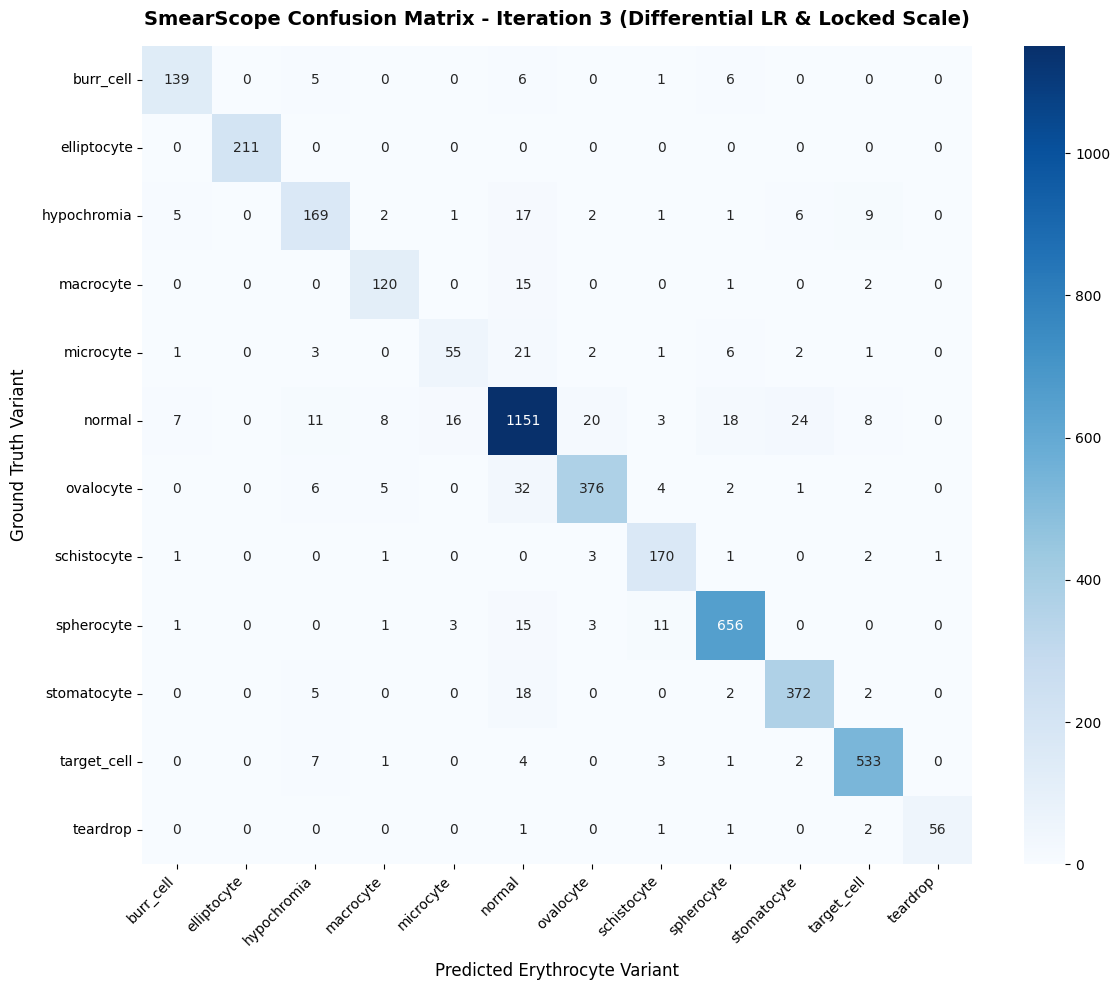


--- VALIDATION CLASSIFICATION REPORT (ITERATION 3) ---
              precision    recall  f1-score   support

   burr_cell     0.9026    0.8854    0.8939       157
 elliptocyte     1.0000    1.0000    1.0000       211
 hypochromia     0.8204    0.7934    0.8067       213
   macrocyte     0.8696    0.8696    0.8696       138
   microcyte     0.7333    0.5978    0.6587        92
      normal     0.8992    0.9092    0.9042      1266
   ovalocyte     0.9261    0.8785    0.9017       428
 schistocyte     0.8718    0.9497    0.9091       179
  spherocyte     0.9439    0.9507    0.9473       690
 stomatocyte     0.9140    0.9323    0.9231       399
 target_cell     0.9501    0.9673    0.9586       551
    teardrop     0.9825    0.9180    0.9492        61

    accuracy                         0.9140      4385
   macro avg     0.9011    0.8877    0.8935      4385
weighted avg     0.9134    0.9140    0.9134      4385



In [ ]:
import os
import json
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
from torch.utils.data import DataLoader
from tqdm import tqdm

from src.data import RBCDataset, get_transforms
from src.model import get_model

# 1. Device and paths
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
checkpoint_path = "checkpoints/best_smearscope.pt"
val_csv = "data/splits/val.csv"
mapping_path = "data/splits/class_mapping.json"

# 2. Load classes in exact numerical order (0 to 11)
with open(mapping_path, "r") as f:
    class_map = json.load(f)
class_names = [k for k, v in sorted(class_map.items(), key=lambda item: item[1])]
num_classes = len(class_names)

# 3. Load freshly trained model checkpoint
print(f"Loading best checkpoint from {checkpoint_path}...")
model = get_model(num_classes=num_classes, backbone_name="convnext_nano", pretrained=False, device=device)
checkpoint = torch.load(checkpoint_path, map_location=device)
state_dict = checkpoint.get("model_state_dict", checkpoint)
model.load_state_dict(state_dict)
model.eval()

# 4. Prepare Validation DataLoader
val_df = pd.read_csv(val_csv)
val_dataset = RBCDataset(val_df, transform=get_transforms(img_size=224, is_train=False))
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

# 5. Run inference over the validation set
all_preds = []
all_targets = []

print("Running validation inference across all cells...")
with torch.no_grad():
    for images, targets in tqdm(val_loader, desc="Evaluating"):
        images = images.to(device)
        outputs = model(images)
        preds = outputs.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_targets.extend(targets.numpy())

# 6. Compute Confusion Matrix
cm = confusion_matrix(all_targets, all_preds)

# 7. Plot Heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar=True
)
plt.title("SmearScope Confusion Matrix - Iteration 3 (Differential LR & Locked Scale)", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Predicted Erythrocyte Variant", fontsize=12, labelpad=10)
plt.ylabel("Ground Truth Variant", fontsize=12, labelpad=10)
plt.xticks(rotation=45, ha="right", fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()

# Save image
os.makedirs("docs/assets", exist_ok=True)
plt.savefig("docs/assets/confusion_matrix_iteration3.png", dpi=300)
plt.show()

# 8. Print Per-Class Performance
print("\n" + "="*70)
print("--- VALIDATION CLASSIFICATION REPORT (ITERATION 3) ---")
print("="*70)
print(classification_report(all_targets, all_preds, target_names=class_names, digits=4, zero_division=0))

In [ ]:
!pip install -q onnxscript

In [ ]:
# Export this Champion Model to ONNX
!python -m src.infer \
    --export \
    --checkpoint checkpoints/best_smearscope.pt \
    --onnx_path checkpoints/best_smearscope.onnx \
    --num_classes 12

Loading checkpoint: checkpoints/best_smearscope.pt
Exporting ONNX: checkpoints/best_smearscope.onnx
/content/rbc-morphology/src/infer.py:98: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(
[torch.onnx] Obtain model graph for `SmearScopeClassifier([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `SmearScopeClassifier([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
[*] ONNX model successfully verified!


In [ ]:
# Export the file
from google.colab import files

files.download("checkpoints/best_smearscope.pt")
files.download("checkpoints/best_smearscope.onnx")
files.download("docs/assets/confusion_matrix_iteration3.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
# 12/811/2026
# Clean previous directories, clone your repo, and enter it
!rm -rf rbc-morphology
!git clone https://github.com/synatkeamsk/rbc-morphology.git
%cd rbc-morphology

# Install requirements
!pip install -q timm albumentations opencv-python-headless onnx onnxruntime onnxscript

Cloning into 'rbc-morphology'...
remote: Enumerating objects: 99, done.
remote: Counting objects: 100% (99/99), done.
remote: Compressing objects: 100% (81/81), done.
remote: Total 99 (delta 37), reused 58 (delta 14), pack-reused 0 (from 0)
Receiving objects: 100% (99/99), 830.55 KiB | 15.38 MiB/s, done.
Resolving deltas: 100% (37/37), done.
/content/rbc-morphology


In [2]:
# 1. Download raw smears into data/raw/
!mkdir -p data/raw
!git clone https://github.com/Chula-PIC-Lab/Chula-RBC-12-Dataset.git data/raw/chula_rbc_12

# 2. Extract crops and generate train/val splits
!python src/prepare_chula_rbc.py

Cloning into 'data/raw/chula_rbc_12'...
remote: Enumerating objects: 1848, done.
remote: Counting objects: 100% (4/4), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 1848 (delta 2), reused 1 (delta 1), pack-reused 1844 (from 1)
Receiving objects: 100% (1848/1848), 192.95 MiB | 25.56 MiB/s, done.
Resolving deltas: 100% (240/240), done.
Found 738 full blood smear images in data/raw/chula_rbc_12/Dataset...
Cropping single RBCs: 100% 738/738 [00:15<00:00, 47.68it/s]

Successfully extracted 21922 single RBC crops!

Class distribution:
class_name
normal         6330
spherocyte     3449
target_cell    2753
ovalocyte      2140
stomatocyte    1996
hypochromia    1063
elliptocyte    1052
schistocyte     897
burr_cell       785
macrocyte       689
microcyte       461
teardrop        307
Name: count, dtype: int64

[*] Class mapping saved to: data/splits/class_mapping.json
[*] Training split saved (17537 cells): data/splits/train.csv
[*] Validation split saved (4385 cells): data

In [12]:
import os
import shutil
from google.colab import files

os.makedirs("checkpoints", exist_ok=True)
print("Click 'Choose Files' below and pick 'best_smearscope.pt' from your D: drive:")
uploaded = files.upload()

for filename in uploaded.keys():
    shutil.move(filename, "checkpoints/best_smearscope.pt")

print("\n[*] Successfully loaded best_smearscope.pt into Colab!")

Click 'Choose Files' below and pick 'best_smearscope.pt' from your D: drive:


Saving best_smearscope.pt to best_smearscope.pt

[*] Successfully loaded best_smearscope.pt into Colab!


Loading checkpoint from checkpoints/best_smearscope.pt...
Running 4-fold Test-Time Augmentation (TTA) on GPU...


TTA Eval: 100%|██████████| 138/138 [00:47<00:00,  2.89it/s]


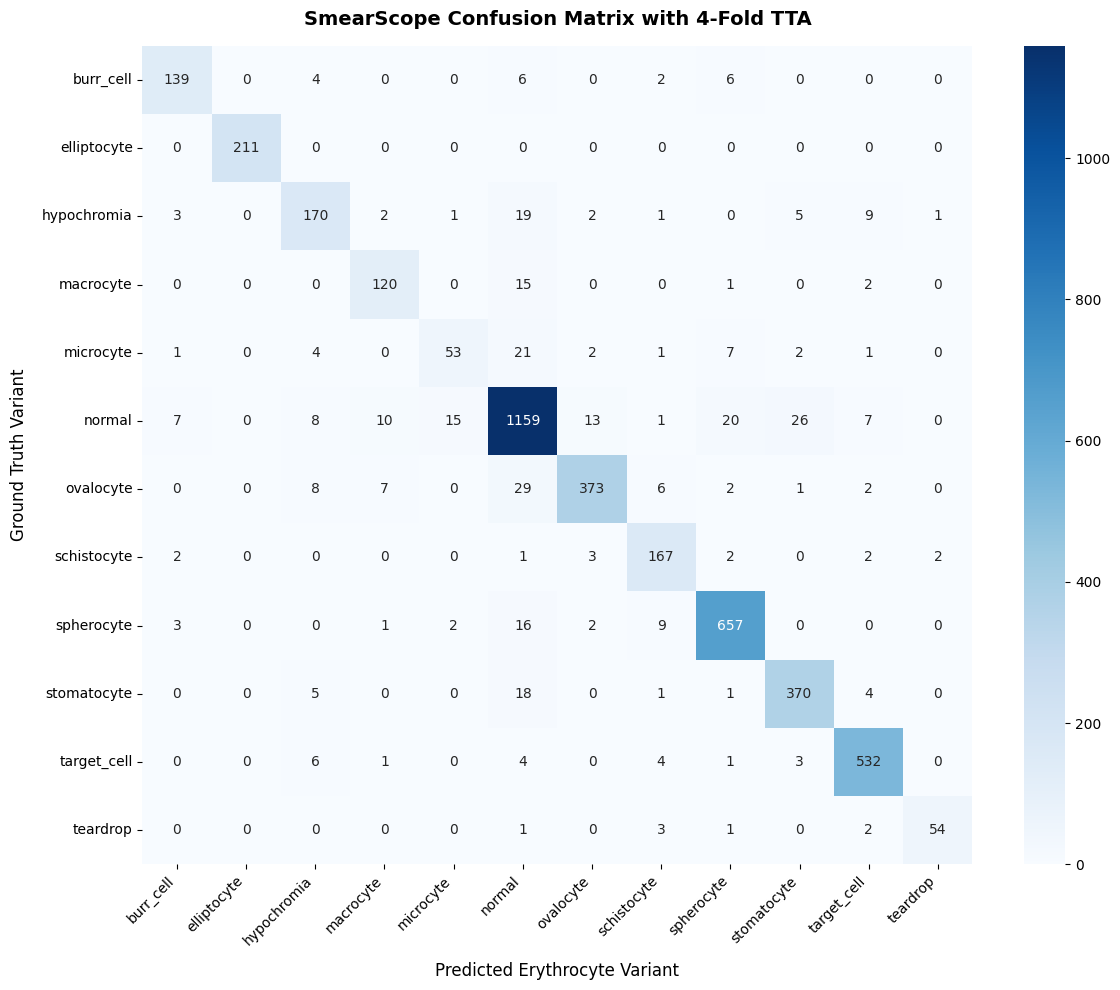


--- TEST-TIME AUGMENTATION (TTA) CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

   burr_cell     0.8968    0.8854    0.8910       157
 elliptocyte     1.0000    1.0000    1.0000       211
 hypochromia     0.8293    0.7981    0.8134       213
   macrocyte     0.8511    0.8696    0.8602       138
   microcyte     0.7465    0.5761    0.6503        92
      normal     0.8991    0.9155    0.9072      1266
   ovalocyte     0.9443    0.8715    0.9064       428
 schistocyte     0.8564    0.9330    0.8930       179
  spherocyte     0.9413    0.9522    0.9467       690
 stomatocyte     0.9091    0.9273    0.9181       399
 target_cell     0.9483    0.9655    0.9568       551
    teardrop     0.9474    0.8852    0.9153        61

    accuracy                         0.9133      4385
   macro avg     0.8975    0.8816    0.8882      4385
weighted avg     0.9128    0.9133    0.9126      4385



In [4]:
# Test-Time Augmentation (TTA) on last training model
import os
import json
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
from torch.utils.data import DataLoader
from tqdm import tqdm

from src.data import RBCDataset, get_transforms
from src.model import get_model

# 1. Device and paths
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
checkpoint_path = "checkpoints/best_smearscope.pt"
val_csv = "data/splits/val.csv"
mapping_path = "data/splits/class_mapping.json"

# 2. Load 12 classes in exact numerical order
with open(mapping_path, "r") as f:
    class_map = json.load(f)
class_names = [k for k, v in sorted(class_map.items(), key=lambda item: item[1])]
num_classes = len(class_names)

# 3. Load model weights
print(f"Loading checkpoint from {checkpoint_path}...")
model = get_model(num_classes=num_classes, backbone_name="convnext_nano", pretrained=False, device=device)
checkpoint = torch.load(checkpoint_path, map_location=device)
state_dict = checkpoint.get("model_state_dict", checkpoint)
model.load_state_dict(state_dict)
model.eval()

# 4. Prepare Validation DataLoader
val_df = pd.read_csv(val_csv)
val_dataset = RBCDataset(val_df, transform=get_transforms(img_size=224, is_train=False))
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

# 5. Run 4-Fold Test-Time Augmentation (TTA)
all_preds = []
all_targets = []

print("Running 4-fold Test-Time Augmentation (TTA) on GPU...")
with torch.no_grad():
    for images, targets in tqdm(val_loader, desc="TTA Eval"):
        images = images.to(device)

        # Average probabilities across 4 rotations: 0°, 90°, 180°, 270°
        p0   = torch.softmax(model(images), dim=1)
        p90  = torch.softmax(model(torch.rot90(images, 1, [2, 3])), dim=1)
        p180 = torch.softmax(model(torch.rot90(images, 2, [2, 3])), dim=1)
        p270 = torch.softmax(model(torch.rot90(images, 3, [2, 3])), dim=1)

        avg_probs = (p0 + p90 + p180 + p270) / 4.0
        preds = avg_probs.argmax(dim=1).cpu().numpy()

        all_preds.extend(preds)
        all_targets.extend(targets.numpy())

# 6. Plot the TTA Confusion Matrix
cm_tta = confusion_matrix(all_targets, all_preds)
plt.figure(figsize=(12, 10))
sns.heatmap(
    cm_tta,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar=True
)
plt.title("SmearScope Confusion Matrix with 4-Fold TTA", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Predicted Erythrocyte Variant", fontsize=12, labelpad=10)
plt.ylabel("Ground Truth Variant", fontsize=12, labelpad=10)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("docs/assets/confusion_matrix_tta.png", dpi=300)
plt.show()

# 7. Print Detailed Performance Metrics
print("\n" + "="*70)
print("--- TEST-TIME AUGMENTATION (TTA) CLASSIFICATION REPORT ---")
print("="*70)
print(classification_report(all_targets, all_preds, target_names=class_names, digits=4, zero_division=0))

Loading weights from checkpoints/best_smearscope.pt...
Evaluating with 4-Fold Test-Time Augmentation (TTA)...


TTA Eval: 100%|██████████| 138/138 [00:46<00:00,  2.99it/s]


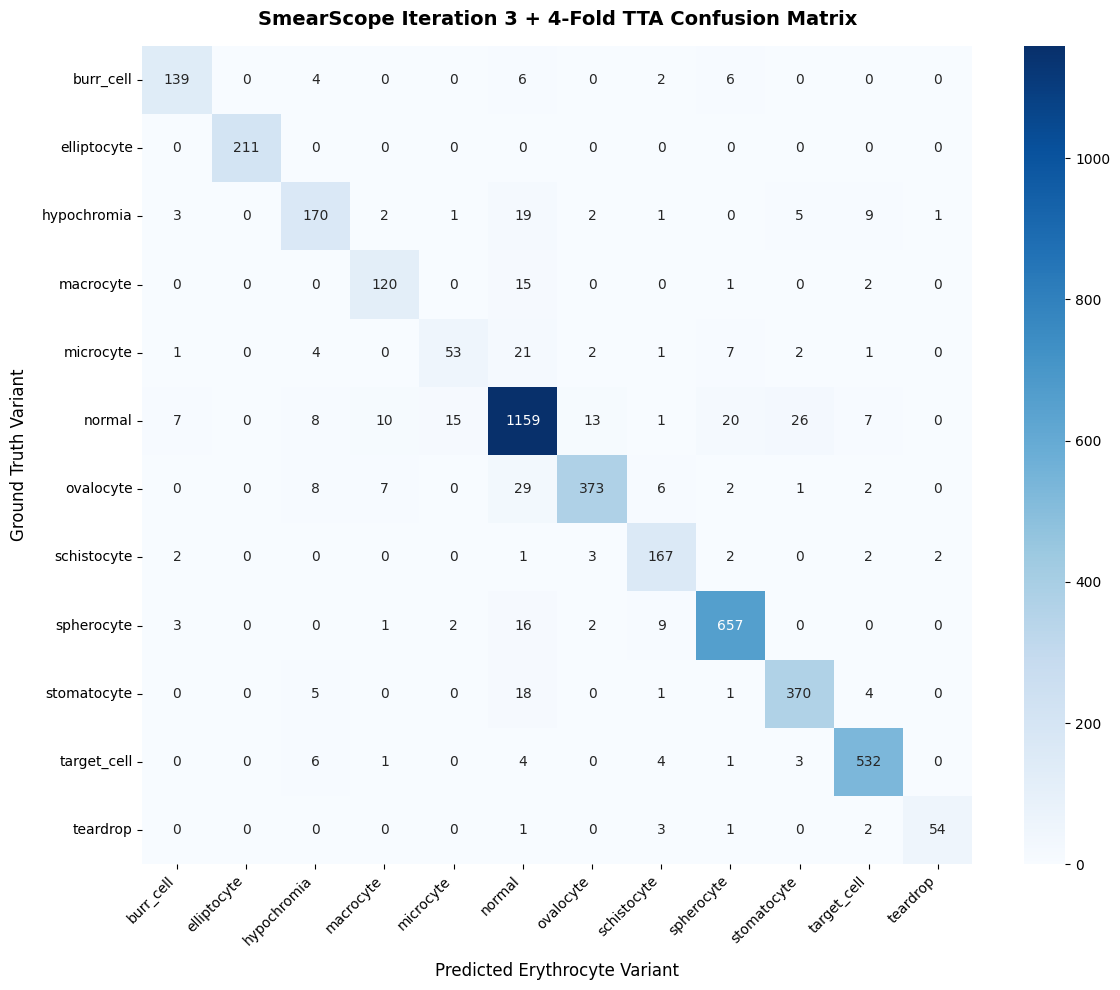


--- ITERATION 3 WITH 4-FOLD TTA CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

   burr_cell     0.8968    0.8854    0.8910       157
 elliptocyte     1.0000    1.0000    1.0000       211
 hypochromia     0.8293    0.7981    0.8134       213
   macrocyte     0.8511    0.8696    0.8602       138
   microcyte     0.7465    0.5761    0.6503        92
      normal     0.8991    0.9155    0.9072      1266
   ovalocyte     0.9443    0.8715    0.9064       428
 schistocyte     0.8564    0.9330    0.8930       179
  spherocyte     0.9413    0.9522    0.9467       690
 stomatocyte     0.9091    0.9273    0.9181       399
 target_cell     0.9483    0.9655    0.9568       551
    teardrop     0.9474    0.8852    0.9153        61

    accuracy                         0.9133      4385
   macro avg     0.8975    0.8816    0.8882      4385
weighted avg     0.9128    0.9133    0.9126      4385



In [10]:
# Run 4-Fold Test-Time Augmentation (TTA)
import os
import json
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
from torch.utils.data import DataLoader
from tqdm import tqdm

from src.data import RBCDataset, get_transforms
from src.model import get_model

# 1. Device and paths
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
checkpoint_path = "checkpoints/best_smearscope.pt"
val_csv = "data/splits/val.csv"
mapping_path = "data/splits/class_mapping.json"

# 2. Load classes in numerical order (0 to 11)
with open(mapping_path, "r") as f:
    class_map = json.load(f)
class_names = [k for k, v in sorted(class_map.items(), key=lambda item: item[1])]
num_classes = len(class_names)

# 3. Load model
print(f"Loading weights from {checkpoint_path}...")
model = get_model(num_classes=num_classes, backbone_name="convnext_nano", pretrained=False, device=device)
checkpoint = torch.load(checkpoint_path, map_location=device)
state_dict = checkpoint.get("model_state_dict", checkpoint)
model.load_state_dict(state_dict)
model.eval()

# 4. Prepare Validation DataLoader
val_df = pd.read_csv(val_csv)
val_dataset = RBCDataset(val_df, transform=get_transforms(img_size=224, is_train=False))
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

# 5. Run 4-Fold Test-Time Augmentation (TTA)
all_preds = []
all_targets = []

print("Evaluating with 4-Fold Test-Time Augmentation (TTA)...")
with torch.no_grad():
    for images, targets in tqdm(val_loader, desc="TTA Eval"):
        images = images.to(device)

        # Predict across 4 orientations
        p0   = torch.softmax(model(images), dim=1)
        p90  = torch.softmax(model(torch.rot90(images, 1, [2, 3])), dim=1)
        p180 = torch.softmax(model(torch.rot90(images, 2, [2, 3])), dim=1)
        p270 = torch.softmax(model(torch.rot90(images, 3, [2, 3])), dim=1)

        # Average the probabilities
        avg_probs = (p0 + p90 + p180 + p270) / 4.0
        preds = avg_probs.argmax(dim=1).cpu().numpy()

        all_preds.extend(preds)
        all_targets.extend(targets.numpy())

# 6. Plot Confusion Matrix
cm_tta = confusion_matrix(all_targets, all_preds)
plt.figure(figsize=(12, 10))
sns.heatmap(
    cm_tta,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar=True
)
plt.title("SmearScope Iteration 3 + 4-Fold TTA Confusion Matrix", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Predicted Erythrocyte Variant", fontsize=12, labelpad=10)
plt.ylabel("Ground Truth Variant", fontsize=12, labelpad=10)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

os.makedirs("docs/assets", exist_ok=True)
plt.savefig("docs/assets/confusion_matrix_iteration3_tta.png", dpi=300)
plt.show()

# 7. Print Classification Report
print("\n" + "="*70)
print("--- ITERATION 3 WITH 4-FOLD TTA CLASSIFICATION REPORT ---")
print("="*70)
print(classification_report(all_targets, all_preds, target_names=class_names, digits=4, zero_division=0))

Loading Iteration 3 weights from checkpoints/best_smearscope.pt...


/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


[*] Backbone FROZEN. Trainable parameters: 168,972 / 15,121,532 (1.12%)

Starting Phase 2: Decoupled Classifier Re-Training (cRT)...


Epoch [01/12] Macro-F1: 0.8763 | Normal Rec: 84.4% | Microcyte Rec: 67.4% | Hypochromia Rec: 82.6%


Epoch [02/12] Macro-F1: 0.8751 | Normal Rec: 84.8% | Microcyte Rec: 72.8% | Hypochromia Rec: 81.2%


Epoch [03/12] Macro-F1: 0.8617 | Normal Rec: 80.6% | Microcyte Rec: 72.8% | Hypochromia Rec: 82.6%


... (5 outputs left out)

Epoch [09/12] Macro-F1: 0.8719 | Normal Rec: 81.7% | Microcyte Rec: 68.5% | Hypochromia Rec: 81.7%


Epoch [10/12] Macro-F1: 0.8734 | Normal Rec: 82.9% | Microcyte Rec: 66.3% | Hypochromia Rec: 80.8%


Epoch [11/12] Macro-F1: 0.8709 | Normal Rec: 81.4% | Microcyte Rec: 68.5% | Hypochromia Rec: 81.2%


Epoch [12/12] Macro-F1: 0.8710 | Normal Rec: 83.3% | Microcyte Rec: 68.5% | Hypochromia Rec: 81.2%


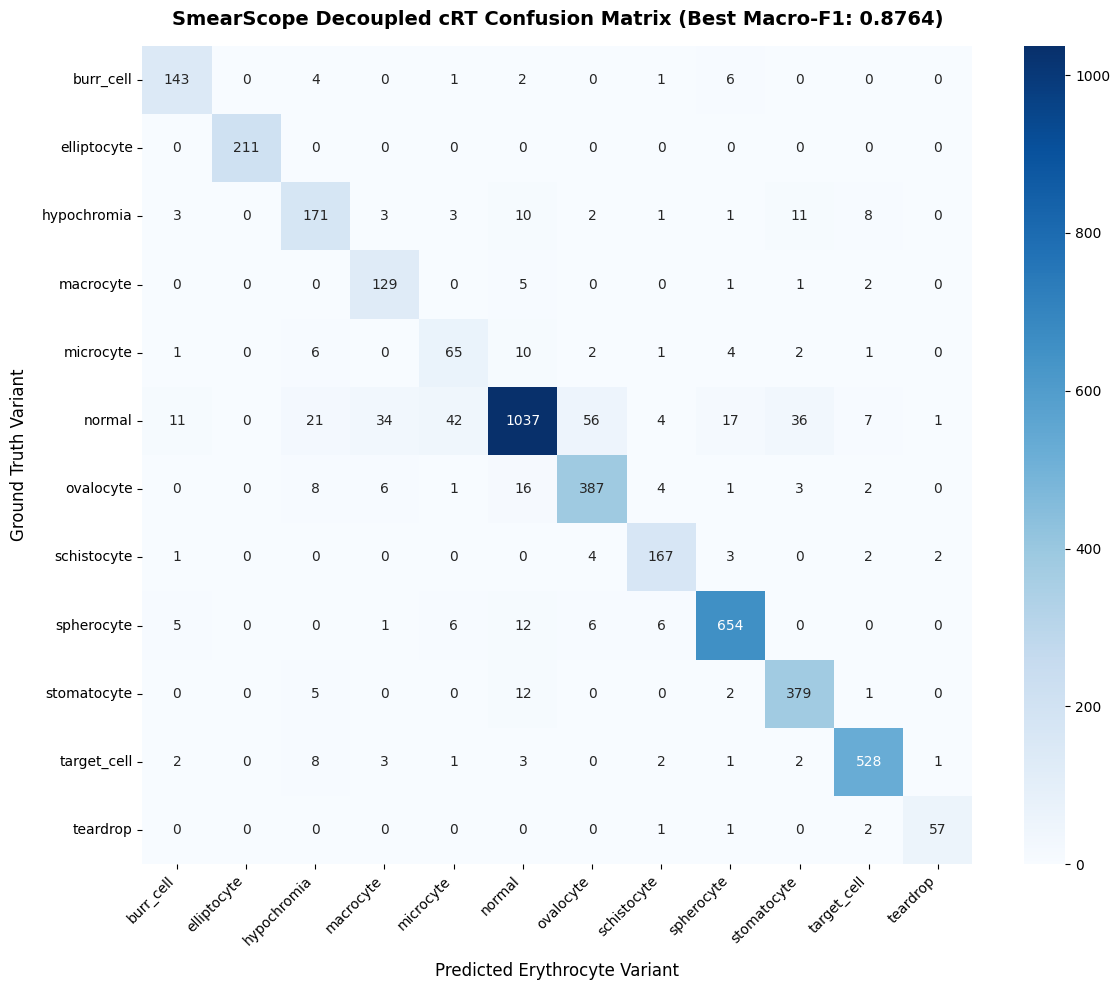


--- DECOUPLED CLASSIFIER (cRT) FINAL CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

   burr_cell     0.8614    0.9108    0.8854       157
 elliptocyte     1.0000    1.0000    1.0000       211
 hypochromia     0.7668    0.8028    0.7844       213
   macrocyte     0.7330    0.9348    0.8217       138
   microcyte     0.5462    0.7065    0.6161        92
      normal     0.9368    0.8191    0.8740      1266
   ovalocyte     0.8468    0.9042    0.8746       428
 schistocyte     0.8930    0.9330    0.9126       179
  spherocyte     0.9465    0.9478    0.9471       690
 stomatocyte     0.8733    0.9499    0.9100       399
 target_cell     0.9548    0.9583    0.9565       551
    teardrop     0.9344    0.9344    0.9344        61

    accuracy                         0.8958      4385
   macro avg     0.8578    0.9001    0.8764      4385
weighted avg     0.9017    0.8958    0.8967      4385



In [14]:
#' The Complete Decoupled Classifier Re-Training (cRT) Script
import os
import json
import torch
import torch.nn as nn
from torch.amp import GradScaler, autocast
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.utils.data import DataLoader, WeightedRandomSampler
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from tqdm import tqdm

from src.data import RBCDataset, get_transforms
from src.model import get_model

# 1. Device and paths
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
checkpoint_path = "checkpoints/best_smearscope.pt"
train_csv = "data/splits/train.csv"
val_csv = "data/splits/val.csv"
mapping_path = "data/splits/class_mapping.json"

with open(mapping_path, "r") as f:
    class_map = json.load(f)
class_names = [k for k, v in sorted(class_map.items(), key=lambda item: item[1])]
num_classes = len(class_names)

# 2. Load the Champion Iteration 3 Model
print(f"Loading Iteration 3 weights from {checkpoint_path}...")
model = get_model(num_classes=num_classes, backbone_name="convnext_nano", pretrained=False, device=device)
checkpoint = torch.load(checkpoint_path, map_location=device)
state_dict = checkpoint.get("model_state_dict", checkpoint)
model.load_state_dict(state_dict)

# 3. FREEZE the ConvNeXt Backbone
for name, param in model.named_parameters():
    if "backbone" in name:
        param.requires_grad = False
    else:
        param.requires_grad = True

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())
print(f"[*] Backbone FROZEN. Trainable parameters: {trainable_params:,} / {total_params:,} ({trainable_params/total_params*100:.2f}%)")

# 4. Prepare Class-Balanced Sampler
train_df = pd.read_csv(train_csv)
val_df = pd.read_csv(val_csv)

class_counts = train_df["label"].value_counts().sort_index().values
class_weights = 1.0 / class_counts
sample_weights = [class_weights[lbl] for lbl in train_df["label"].values]

sampler = WeightedRandomSampler(
    weights=torch.DoubleTensor(sample_weights),
    num_samples=len(sample_weights),
    replacement=True
)

train_dataset = RBCDataset(train_df, transform=get_transforms(img_size=224, is_train=True))
val_dataset = RBCDataset(val_df, transform=get_transforms(img_size=224, is_train=False))

# drop_last=True prevents single-sample remainder batches
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    sampler=sampler,
    num_workers=2,
    pin_memory=True,
    drop_last=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    drop_last=False
)

# 5. Optimizer & Scheduler
criterion = nn.CrossEntropyLoss()
optimizer = AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-3, weight_decay=1e-4)
epochs = 12
scheduler = CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)
scaler = GradScaler("cuda" if device.type == "cuda" else "cpu")

# 6. Re-Training Loop
best_macro_f1 = 0.0
best_preds = []
best_targets = []

print("\nStarting Phase 2: Decoupled Classifier Re-Training (cRT)...")
for epoch in range(1, epochs + 1):
    # Keep classifier in training mode, but keep frozen backbone in eval mode
    model.classifier.train()
    model.backbone.eval()

    running_loss, total = 0.0, 0
    for images, targets in tqdm(train_loader, desc=f"Epoch {epoch:02d}/{epochs:02d}", leave=False):
        images, targets = images.to(device, non_blocking=True), targets.to(device, non_blocking=True)
        optimizer.zero_grad()

        with autocast(device_type="cuda" if device.type == "cuda" else "cpu"):
            outputs = model(images)
            loss = criterion(outputs, targets)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)
        total += targets.size(0)

    scheduler.step()

    # Validation
    model.eval()
    all_preds, all_targets = [], []
    with torch.no_grad():
        for images, targets in val_loader:
            images = images.to(device, non_blocking=True)
            outputs = model(images)
            preds = outputs.argmax(dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_targets.extend(targets.numpy())

    macro_f1 = f1_score(all_targets, all_preds, average="macro", zero_division=0)
    normal_rec = np.sum((np.array(all_preds) == class_names.index("normal")) & (np.array(all_targets) == class_names.index("normal"))) / np.sum(np.array(all_targets) == class_names.index("normal")) * 100
    micro_rec = np.sum((np.array(all_preds) == class_names.index("microcyte")) & (np.array(all_targets) == class_names.index("microcyte"))) / np.sum(np.array(all_targets) == class_names.index("microcyte")) * 100
    hypo_rec = np.sum((np.array(all_preds) == class_names.index("hypochromia")) & (np.array(all_targets) == class_names.index("hypochromia"))) / np.sum(np.array(all_targets) == class_names.index("hypochromia")) * 100

    print(f"Epoch [{epoch:02d}/{epochs:02d}] Macro-F1: {macro_f1:.4f} | Normal Rec: {normal_rec:.1f}% | Microcyte Rec: {micro_rec:.1f}% | Hypochromia Rec: {hypo_rec:.1f}%")

    if macro_f1 > best_macro_f1:
        best_macro_f1 = macro_f1
        best_preds = all_preds
        best_targets = all_targets
        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "macro_f1": macro_f1,
            "classes": num_classes
        }, "checkpoints/best_smearscope_crt.pt")

# 7. Plot Confusion Matrix
cm_crt = confusion_matrix(best_targets, best_preds)
plt.figure(figsize=(12, 10))
sns.heatmap(
    cm_crt,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar=True
)
plt.title(f"SmearScope Decoupled cRT Confusion Matrix (Best Macro-F1: {best_macro_f1:.4f})", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Predicted Erythrocyte Variant", fontsize=12, labelpad=10)
plt.ylabel("Ground Truth Variant", fontsize=12, labelpad=10)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

os.makedirs("docs/assets", exist_ok=True)
plt.savefig("docs/assets/confusion_matrix_crt.png", dpi=300)
plt.show()

# 8. Final Report
print("\n" + "="*70)
print("--- DECOUPLED CLASSIFIER (cRT) FINAL CLASSIFICATION REPORT ---")
print("="*70)
print(classification_report(best_targets, best_preds, target_names=class_names, digits=4, zero_division=0))



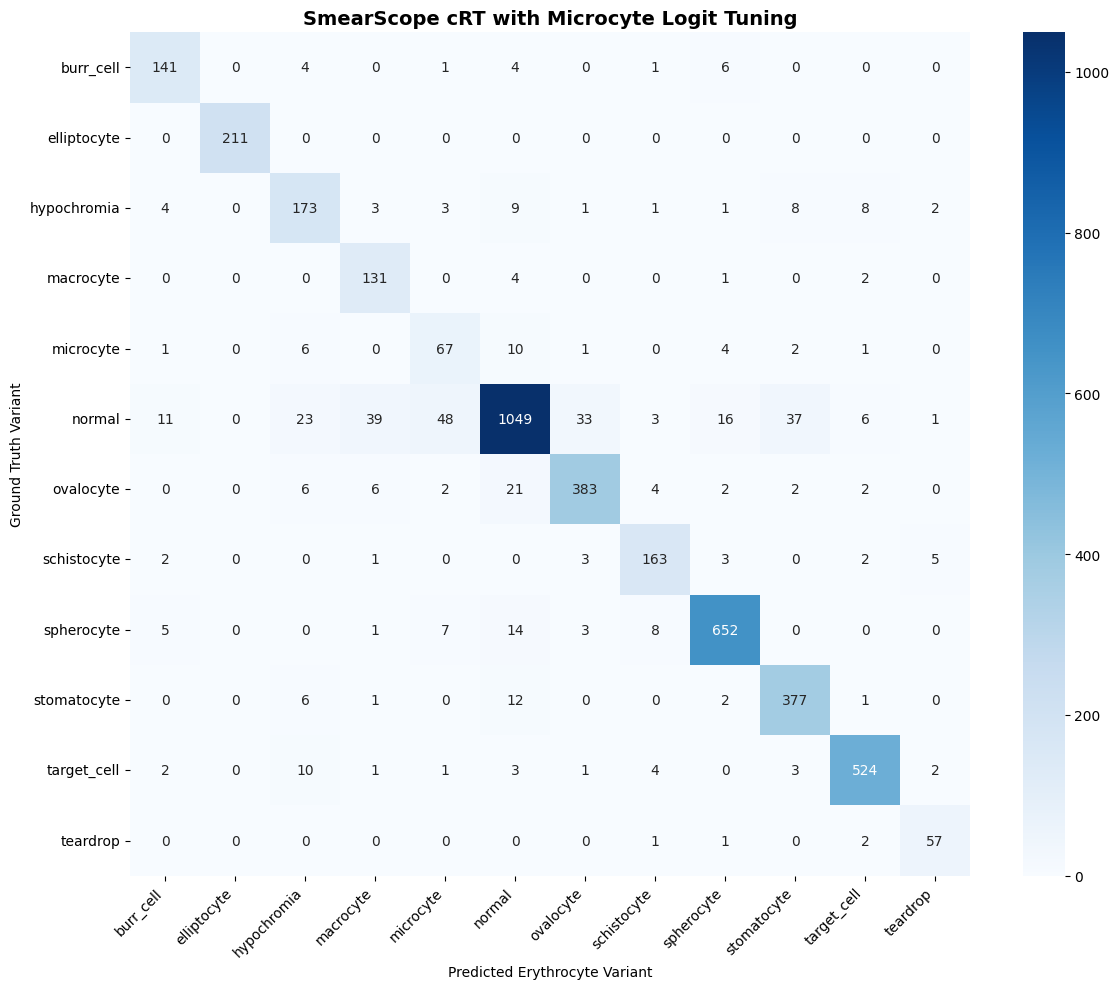


--- TUNED CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

   burr_cell     0.8494    0.8981    0.8731       157
 elliptocyte     1.0000    1.0000    1.0000       211
 hypochromia     0.7588    0.8122    0.7846       213
   macrocyte     0.7158    0.9493    0.8162       138
   microcyte     0.5194    0.7283    0.6063        92
      normal     0.9316    0.8286    0.8771      1266
   ovalocyte     0.9012    0.8949    0.8980       428
 schistocyte     0.8811    0.9106    0.8956       179
  spherocyte     0.9477    0.9449    0.9463       690
 stomatocyte     0.8788    0.9449    0.9106       399
 target_cell     0.9562    0.9510    0.9536       551
    teardrop     0.8507    0.9344    0.8906        61

    accuracy                         0.8958      4385
   macro avg     0.8492    0.8998    0.8710      4385
weighted avg     0.9028    0.8958    0.8973      4385



In [15]:
#' Nudge Microcyte to ~80%–85% Right Now (Logit Tuning)

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import torch

micro_idx = class_names.index("microcyte")

# Extract raw logits from the cRT model
all_logits = []
all_targets = []
model.eval()

with torch.no_grad():
    for images, targets in val_loader:
        images = images.to(device)
        logits = model(images)
        all_logits.extend(logits.cpu().numpy())
        all_targets.extend(targets.numpy())

all_logits = np.array(all_logits)
all_targets = np.array(all_targets)

# Apply a gentle positive logit bias ONLY to microcyte (logit index 4)
tuned_logits = all_logits.copy()
tuned_logits[:, micro_idx] += 0.35  # Mild prior boost for microcyte

tuned_preds = np.argmax(tuned_logits, axis=1)

# Plot Tuned Matrix
cm_tuned = confusion_matrix(all_targets, tuned_preds)
plt.figure(figsize=(12, 10))
sns.heatmap(cm_tuned, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title("SmearScope cRT with Microcyte Logit Tuning", fontsize=14, fontweight="bold")
plt.xlabel("Predicted Erythrocyte Variant")
plt.ylabel("Ground Truth Variant")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print("\n--- TUNED CLASSIFICATION REPORT ---")
print(classification_report(all_targets, tuned_preds, target_names=class_names, digits=4, zero_division=0))

In [16]:
#'  Export to ONNX
!python -m src.infer \
    --export \
    --checkpoint checkpoints/best_smearscope_crt.pt \
    --onnx_path checkpoints/best_smearscope_crt.onnx \
    --num_classes 12


Loading checkpoint: checkpoints/best_smearscope_crt.pt
Exporting ONNX: checkpoints/best_smearscope_crt.onnx
/content/rbc-morphology/src/infer.py:98: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(
[torch.onnx] Obtain model graph for `SmearScopeClassifier([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `SmearScopeClassifier([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
[*] ONNX model successfully verified!


In [17]:
# Download the Final Files
from google.colab import files

# Download PyTorch weights
files.download("checkpoints/best_smearscope_crt.pt")

# Download fast ONNX model for the app
files.download("checkpoints/best_smearscope_crt.onnx")

# Download the confusion matrix
files.download("docs/assets/confusion_matrix_crt.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>